# Six traditional text-classification baselines

Can a model predict the 31 psychosocial tags from a post's text? Before
using a large encoder, compare six simpler baselines: Logistic Regression,
Linear SVM, Multinomial Naive Bayes, Random Forest, SGD Logistic, and XGBoost.

**Reading route:** tags as yes/no decisions → words as TF-IDF features →
six ways to learn → held-out development folds → one final test comparison.
Only `text_clean` is an input; TBe/PBu values remain analysis metadata.
No real model scores are bundled in this notebook.

## Connect to the shared project files

The `src/` folder is the shared toolbox. It holds the codebook and functions used
by multiple notebooks. The next cell finds it from the project root or `notebooks/`.
Keep the complete repository together. On Kaggle or Colab, extract or attach the
complete repository and set `PROJECT_ROOT` to its location when necessary.

Install the repository requirements before running the notebook. The setup cell
prints the root and label count so you can check the selected files. Data and
generated results remain in the ignored project folders.

In [ ]:
from pathlib import Path
import os
import sys

# Leave None when running from the repository root or notebooks/.
# On Kaggle/Colab, set this to the extracted repository directory when needed.
PROJECT_ROOT = os.environ.get("MINDMINER_PROJECT_ROOT")
if PROJECT_ROOT:
    REPO_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
else:
    here = Path.cwd().resolve()
    REPO_ROOT = next((p for p in [here, *here.parents]
                      if (p / "src/mindminer_codebook.py").is_file()), None)
if REPO_ROOT is None or not (REPO_ROOT / "src/mindminer_codebook.py").is_file():
    raise FileNotFoundError("Extract the complete MindMiner repository and set PROJECT_ROOT to its folder.")
sys.path.insert(0, str(REPO_ROOT / "src"))
RUN_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else REPO_ROOT
from mindminer_codebook import CODEBOOK_VERSION, CODEBOOK_SHA256, CODEBOOK, FIELDS, TAGS, LABELS
print("Project root:", REPO_ROOT)
print("Codebook:", CODEBOOK_VERSION, "| tags:", len(LABELS))

## 1. Choose settings before evaluating

The processed dataset defaults to `data/processed/easy_dataset.csv`.
Set `DATA_FILE` for another CSV/Excel file. The first five estimators use
CPU. XGBoost can select CUDA when both its build and a visible GPU support
it; the chosen device is printed. Its parameters remain those in the
supplied notebook. Seeds help repeatability without guaranteeing identical
results across all hardware and library versions.

In [ ]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
import subprocess
import xgboost
from xgboost import XGBClassifier

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

import importlib
import mindminer_utils
importlib.reload(mindminer_utils)

from mindminer_utils import (
    LABELS, find_data_file, load_data, encode_labels, make_folds,
    save_fold_plan, metrics, write_evaluation, summarize_cv, save_json, save_classification_reports,
)

DATA_FILE = os.environ.get("MINDMINER_DATA_FILE", str(REPO_ROOT / "data/processed/easy_dataset.csv"))
OUTPUT = RUN_ROOT / "results/traditional"
SEED = 42
N_SPLITS = 5
MAX_FEATURES = 20_000
CPU_JOBS = max(1, min(4, os.cpu_count() or 1))
def choose_xgb_device():
    # GPU use requires both a CUDA-enabled XGBoost build and a visible NVIDIA GPU.
    if not xgboost.build_info().get("USE_CUDA", False):
        return "cpu"
    if os.environ.get("CUDA_VISIBLE_DEVICES") in {"", "-1"}:
        return "cpu"
    try:
        status = subprocess.run(
            ["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=5,
        )
        return "cuda" if status.returncode == 0 and status.stdout.strip() else "cpu"
    except (OSError, subprocess.TimeoutExpired):
        return "cpu"


XGB_DEVICE = choose_xgb_device()  # Override with "cpu" or "cuda" if desired.

SAVE_FINAL_MODELS = False  # True saves fitted pipelines for later predictions.

OUTPUT.mkdir(parents=True, exist_ok=True)
print(f"scikit-learn uses CPU; parallel workers: {CPU_JOBS}")

print(f"XGBoost {xgboost.__version__} | device: {XGB_DEVICE}")

## 2. Make one yes/no target per tag

A post may mention a family conflict, anxiety, and advice seeking together.
We encode its selected tags as 1 and its unselected tags as 0. There are
**31 columns: 10 stressors, 7 relationships, 8 emotions, 6 responses**.

The shared helper validates the schema and labels, handles declared empty
markers such as `not stated`, removes empty text, and handles exact text
duplicates. Missing annotations must be completed before supervised training.
Actual post counts are computed from the file; none are hard-coded here.

Original train + val becomes development. Test stays separate. Five folds
balance target tags and TBe/PBu groups as far as possible; the group values
are never predictive features. Identical input rows, seed, and fold count
give matching development folds in this and the transformer notebook.

In [ ]:
data_path = find_data_file(DATA_FILE)
all_posts, dev, test, audit = load_data(data_path)
y_dev, y_test = encode_labels(dev), encode_labels(test)
folds = make_folds(dev, y_dev, N_SPLITS, SEED)
save_fold_plan(dev, y_dev, folds, OUTPUT)
save_json(OUTPUT / "run_settings.json", {
    **audit, "seed": SEED, "n_splits": N_SPLITS, "max_features": MAX_FEATURES,
    "input_column": "text_clean", "target_labels": LABELS,
    "thresholds": "0 for SVM margins; 0.5 for probabilities",
    "xgboost_version": xgboost.__version__, "xgboost_device": XGB_DEVICE,
    "xgboost_tree_method": "hist",
})
display(pd.Series(y_dev.sum(axis=0), index=LABELS, name="development_positive_posts").to_frame())

## 3. How does a sentence become a feature vector?

A feature is one measurable input to a classifier. Here it is a word or
two-word phrase. TF-IDF weights a term using its frequency in a post and
its frequency across training posts. The weights are normalized per post.

`ngram_range=(1, 2)` includes words and two-word phrases such as “not happy.”
`max_features=20000` caps vocabulary size, not sentence length. `min_df=2`
keeps terms seen in at least two training posts. Sublinear term frequency
reduces the effect of repeatedly saying the same word.

The next miniature example shows the actual vectorizer output on invented
text. Its vocabulary is for teaching only, not reused in the experiment.

In [ ]:
toy_texts = ['family conflict makes me anxious', 'family support helps me cope', 'I am not happy about conflict']
toy_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1, token_pattern=r'(?u)\b\w+\b')
toy_matrix = toy_vectorizer.fit_transform(toy_texts)
display(pd.DataFrame(toy_matrix.toarray(), columns=toy_vectorizer.get_feature_names_out()).round(3))

## 4. How do the six models learn?

| Model | What it learns | How it produces a tag decision |
| --- | --- | --- |
| Logistic Regression | A weight for each feature plus an intercept | Combine weighted features; sigmoid gives a probability score |
| Linear SVM | A linear separating boundary with a margin | The side of the boundary determines yes/no; distance gives a margin score |
| Multinomial Naive Bayes | Smoothed word evidence for each binary class | Combine feature evidence using its conditional-independence assumption |
| Random Forest | Many trees trained on sampled data and feature choices | Average tree probability estimates for the binary tag |
| SGD Logistic | Logistic weights learned through stochastic gradient updates | Apply the learned logistic decision rule |
| XGBoost | Trees added sequentially to reduce training loss | Sum tree contributions into a margin and apply the logistic link |

**One-vs-rest** fits a separate binary estimator for each tag. A post can
therefore receive several positive predictions. LR and SVM learn linear
boundaries in the many-dimensional TF-IDF space, not a line across the
original sentence. Random Forest averages tree probability estimates;
XGBoost adds trees sequentially rather than voting among independent trees.

The `Pipeline` keeps TF-IDF fitting inside each training fold. This prevents
held-out vocabulary and document frequencies from influencing training.
SVM margins use a zero decision boundary and are not probabilities. AP/AUC
can use ranking scores; their interpretation does not turn margins into
calibrated probabilities.

Class-weight and estimator settings are kept from the supplied experiment.
There is no inner tuning loop or outer-fold early stopping in this notebook.

In [ ]:
# One-vs-rest means: train one yes/no classifier for each of the 31 labels.
models = {
    "LogisticRegression": LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=SEED),
    "LinearSVM": LinearSVC(C=1.0, class_weight="balanced", max_iter=5000, random_state=SEED),
    "MultinomialNB": MultinomialNB(alpha=1.0),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=None, min_samples_leaf=2,
                                            class_weight="balanced_subsample", n_jobs=1, random_state=SEED),
    "SGDLogistic": SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=2000, tol=1e-3,
                                 class_weight="balanced", random_state=SEED),
    "XGBoost": XGBClassifier(
        objective="binary:logistic", eval_metric="logloss",
        n_estimators=200, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        tree_method="hist", device=XGB_DEVICE,
        n_jobs=CPU_JOBS, random_state=SEED,
    ),
}


def build_pipeline(base_model):
    # XGBoost parallelizes internally; one head at a time avoids nested workers and GPU contention.
    ovr_jobs = 1 if isinstance(base_model, XGBClassifier) else CPU_JOBS
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2), max_features=MAX_FEATURES, min_df=2,
            max_df=1.0, sublinear_tf=True, stop_words=None,
            token_pattern=r"(?u)\b\w+\b", dtype=np.float32,
        )),
        ("classifier", OneVsRestClassifier(clone(base_model), n_jobs=ovr_jobs)),
    ])


def predict_labels(model, texts):
    prediction = model.predict(texts).astype(int)
    # SVM scores are margins, not probabilities. Both can be used for AP/AUC.
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(texts)
    else:
        scores = model.decision_function(texts)
    return prediction, np.asarray(scores)

### Work through one prediction with invented numbers

Suppose two TF-IDF feature values are 0.8 and 0.5. A logistic classifier
multiplies them by learned weights, adds an intercept, and applies sigmoid.
The same weighted-sum form can describe a linear SVM's decision score, but
SVM training chooses its boundary differently and does not make that score
a probability. SGD Logistic uses logistic prediction with a different
optimization procedure.

A small forest might return tree probabilities 0.1, 0.8, and 0.9 for one tag.
Their average is 0.6, which gives a positive decision at threshold 0.5.
XGBoost instead adds tree contributions to a margin before applying sigmoid.
These numbers are teaching examples, not fitted project outputs.

In [ ]:
import math

x = [0.8, 0.5]
weights = [1.2, 0.6]
intercept = -0.7
logit = sum(value * weight for value, weight in zip(x, weights)) + intercept
logistic_probability = 1 / (1 + math.exp(-logit))
forest_probability = sum([0.1, 0.8, 0.9]) / 3
# These tree contributions already include their shrinkage/learning-rate effect.
boosted_margin = -0.2 + 0.4 - 0.1
boosted_probability = 1 / (1 + math.exp(-boosted_margin))
print(f'Fictional logistic example: logit={logit:.3f}, probability={logistic_probability:.3f}')
print(f'Fictional forest: mean tree probability={forest_probability:.3f}')
print(f'Fictional boosting: summed margin={boosted_margin:.3f}, probability={boosted_probability:.3f}')

For a simple Naive Bayes illustration with one observed word, equal prior
class probabilities, and word likelihoods 0.3 in positive posts and 0.1 in
negative posts, the unnormalized scores are 0.15 and 0.05. Normalizing gives
0.75 for the positive class. Real MultinomialNB combines feature evidence
across the vector, with smoothing. This arithmetic illustrates its probability
model; it is not a parameter estimate from your dataset.

## Read the development-fold plan

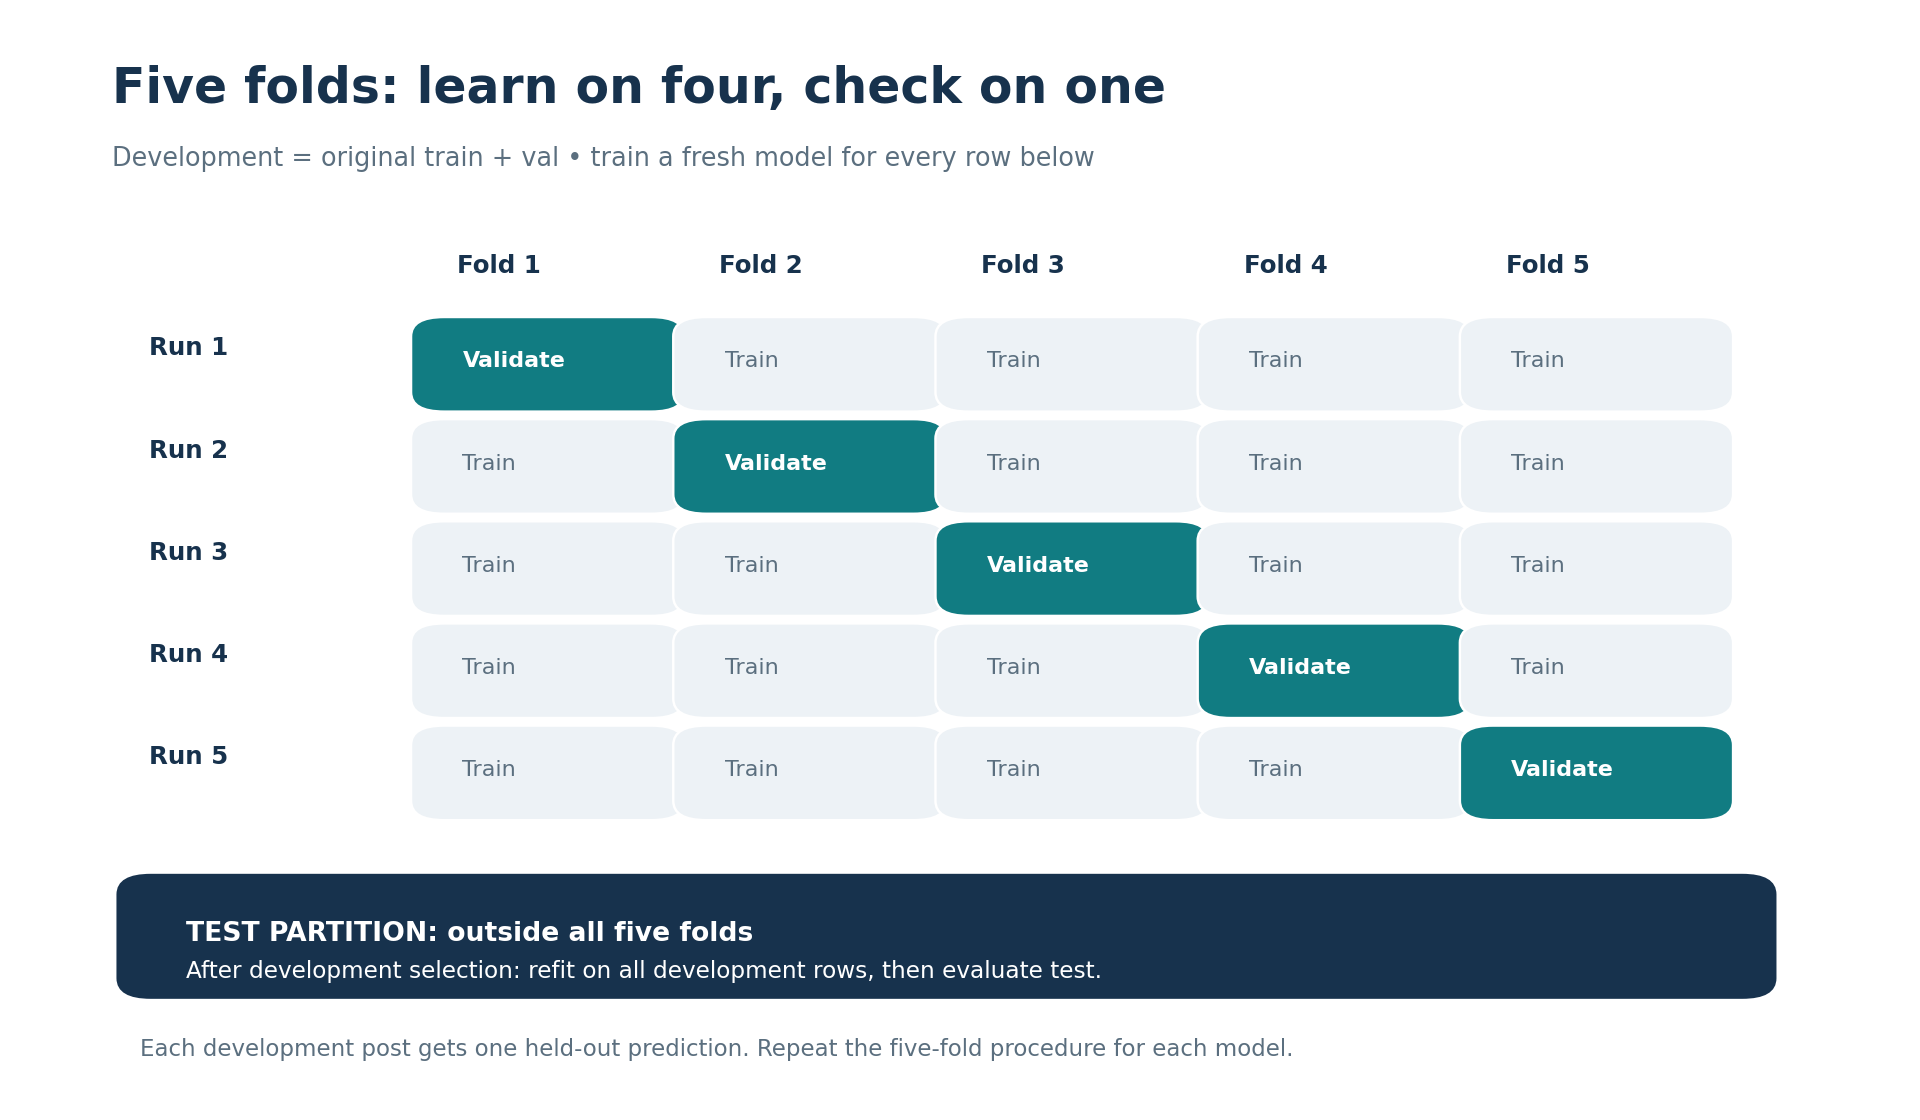

For each model, create a new pipeline on four folds and predict the held-out fifth. Repeat until each development post has one out-of-fold prediction.

## 5. Compare models on held-out development data

Macro F1 gives each of the 31 tags equal weight. Micro F1 combines the
positive-decision counts across tags. Out-of-fold reports pool the held-out
predictions; their F1 need not equal the average of five fold-level F1 scores.
Select the model by mean development macro F1 before viewing test scores.

With six models and five folds, this cell fits 30 pipelines. Each pipeline
contains its own TF-IDF vocabulary and one-vs-rest estimators. The final
test stage adds six development fits, for 36 top-level fits in total.

In [ ]:
cv_rows = []
for model_name, base_model in models.items():
    oof_pred = np.zeros_like(y_dev)
    oof_scores = np.zeros(y_dev.shape, dtype=np.float32)
    for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
        # This new pipeline learns TF-IDF using this fold's training rows only.
        model = build_pipeline(base_model)
        model.fit(dev.iloc[train_idx]["text_clean"], y_dev[train_idx])
        prediction, scores = predict_labels(model, dev.iloc[val_idx]["text_clean"])
        oof_pred[val_idx], oof_scores[val_idx] = prediction, scores
        result = metrics(y_dev[val_idx], prediction, scores)
        cv_rows.append({"model": model_name, "fold": fold_number, **result})
        save_classification_reports(y_dev[val_idx], prediction, OUTPUT / model_name / f"fold_{fold_number}", print_report=False)
        print(f"{model_name} | fold {fold_number}/{N_SPLITS} | macro F1={result['f1_macro']:.3f}")
    write_evaluation(dev, y_dev, oof_pred, oof_scores, OUTPUT / model_name / "development_oof")

cv_summary = summarize_cv(cv_rows, OUTPUT)
display(cv_summary[["f1_macro_mean", "f1_macro_std", "f1_micro_mean", "f1_micro_std"]])
selected_model = cv_summary.index[0]
save_json(OUTPUT / "selected_by_cv.json", {"model": selected_model, "selection_metric": "mean development macro F1"})
print("Model selected before viewing test results:", selected_model)

## 6. Refit and evaluate the final test partition

Each predeclared model is trained fresh on all development rows, then
evaluated on the separate test rows. The chosen model remains the one
selected by development scores. Do not change settings in response to this
table and then call the same test set untouched.

A classification report gives precision, recall, F1, and positive support
per tag. Exact-match accuracy demands every tag be correct for a post.
Hamming loss counts the fraction of wrong post–tag decisions. Undefined
P/R/F1 use zero; AP/AUC include only supported tags, as documented in
`docs/RESULTS_GUIDE.md`. Reference labels may themselves be imperfect.

In [ ]:
# Fit all six predeclared models on development data and evaluate test once.
# Choose models with CV above; do not tune settings after inspecting this table.
test_rows = []
for model_name, base_model in models.items():
    model = build_pipeline(base_model)
    model.fit(dev["text_clean"], y_dev)
    prediction, scores = predict_labels(model, test["text_clean"])
    result = write_evaluation(test, y_test, prediction, scores, OUTPUT / model_name / "test")
    test_rows.append({"model": model_name, **result})
    if SAVE_FINAL_MODELS:
        joblib.dump({"pipeline": model, "labels": LABELS}, OUTPUT / model_name / "fitted_pipeline.joblib")

test_comparison = pd.DataFrame(test_rows).set_index("model")
test_comparison.to_csv(OUTPUT / "test_comparison.csv")
display(test_comparison[["precision_macro", "recall_macro", "f1_macro", "f1_micro", "hamming_loss", "exact_match_accuracy"]])

## 7. Read the development comparison chart

Bar length is mean development macro F1. Error bars show sample standard
deviation across folds, not confidence intervals. A bigger mean alone does
not establish a statistically reliable difference between two models.

In [ ]:
plot_data = cv_summary.sort_values("f1_macro_mean")
ax = plot_data["f1_macro_mean"].plot.barh(
    xerr=plot_data["f1_macro_std"], color="#2563eb", figsize=(8, 4), capsize=4,
)
ax.set(xlabel=f"Development macro F1 (mean ± SD across {N_SPLITS} folds)", ylabel="", xlim=(0, 1))
plt.tight_layout()
plt.savefig(OUTPUT / "cv_macro_f1.png", dpi=160)
plt.show()